# Phase 3 · Methodology and preprocessing

**Project 1 · FAA · breast_cancer (classification)**

**What this notebook does:** it defines **the rules of the game** under which the five learners will be compared in the following phases: how the data is split, what is measured, what we compare against, how data leakage is avoided and how we decide whether a difference is real.

**How to read it:** every line of code has a comment; below the results there is a *What we see / Decision* box. We do **not** train any of the five learners yet.

## Methodology scheme

```
569 tumours
 ├── 114 TEST  (20%)  → set aside, used ONCE at the end (Phase 6)
 └── 455 TRAIN (80%)
        └── repeated cross-validation 5 × 5 = 25 folds  (compare learners)
              └── in each fold: 364 train / 91 validation
                    └── (Phase 5) inner validation with 3 folds to choose hyperparameters
```


### Cell 1: import the libraries

We import the libraries. This time we add `scipy.stats` (statistical tests) and several scikit-learn tools to create folds, metrics and pipelines.

In [1]:
import polars as pl  # polars: reads and manipulates the data table
import numpy as np  # numpy: numerical computing with arrays
import matplotlib.pyplot as plt  # matplotlib: draws the plots
from matplotlib.patches import FancyBboxPatch  # FancyBboxPatch: rounded boxes for the pipeline diagram
from pathlib import Path  # Path: handles folder and file paths
from scipy import stats  # stats: statistical tests and Student's t distribution
from sklearn.base import clone  # clone: copies a model without training
from sklearn.dummy import DummyClassifier  # DummyClassifier: dumb model used as a baseline
from sklearn.linear_model import LogisticRegression  # logistic regression: only to test the machinery
from sklearn.metrics import confusion_matrix, matthews_corrcoef, f1_score, roc_auc_score, brier_score_loss, log_loss  # metrics
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold  # split the data and create folds
from sklearn.naive_bayes import GaussianNB  # Naive Bayes: only for the statistical-test example
from sklearn.pipeline import Pipeline  # Pipeline: chains preprocessing + model
from sklearn.preprocessing import FunctionTransformer, StandardScaler  # preprocessing transformations

### Cell 2: load the data and repeat the Phase 2 split

We load the data and recode the diagnosis as in Phase 2 (`malignant = 1`).

In [2]:
path = Path("datasets/breast_cancer.csv.zst")  # the data file is in the datasets folder
data = pl.read_csv(path)  # read the file
data = data.with_columns((1 - pl.col("target")).alias("malignant")).drop("target")  # malignant = 1 (in the file benign = 1)
figures_dir = path.parent.parent / "figures" / "03_methodology"  # folder for this phase's plots
figures_dir.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
columns = [c for c in data.columns if c != "malignant"]  # names of the 30 features
X = data.select(columns).to_numpy()  # feature matrix (569 x 30)
y = data["malignant"].to_numpy()  # diagnosis vector (1 = malignant)
print("Data:", X.shape, "| malignant:", int(y.sum()))  # check sizes

Data: (569, 30) | malignant: 212


### Cell 3: set the test set aside (exactly as in Phase 2)

We repeat **exactly** the Phase 2 split (same seed 42, 20% test, stratified). The test set (114 rows) stays set aside and is **not used until Phase 6**. Everything that follows is done with the 455 training rows.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)  # same seed 42 => same rows as in Phase 2
print("Train:", X_train.shape[0], "rows | Test:", X_test.shape[0], "rows")  # 455 and 114
print(f"% malignant in train: {y_train.mean():.1%} | in test: {y_test.mean():.1%}")  # same proportion in both

Train: 455 rows | Test: 114 rows
% malignant in train: 37.4% | in test: 36.8%


**What we see:** 455 training and 114 test rows, with 37.4% and 36.8% malignant. **Decision:** always stratify.

### Cell 4: create the repeated cross-validation

**The problem:** with only 455 rows, a single validation split would give a different result depending on which rows happen to fall in it.

**The solution:** *repeated cross-validation*. We divide the training set into 5 chunks; we train on 4 and validate on 1, and rotate. This is repeated 5 times with different splits: **5 × 5 = 25 folds**. So we get 25 results per model and can measure the **dispersion** (not just the mean).

All five learners will use **the same 25 folds** (same seed), which makes the comparison fair.

In [4]:
cross_validation = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)  # 5 chunks, repeated 5 times, always stratified
folds = list(cross_validation.split(X_train, y_train))  # list of (training rows, validation rows)
print("Number of folds:", len(folds))  # 5 x 5 = 25
train_idx, val_idx = folds[0]  # look at the first fold
print("First fold -> trains on", len(train_idx), "rows and validates on", len(val_idx))  # 364 and 91
for i in range(5):  # check the 5 folds of the first repetition
    print(f"  fold {i + 1}: {y_train[folds[i][1]].mean():.1%} malignant in validation")  # must be ~37%

Number of folds: 25
First fold -> trains on 364 rows and validates on 91
  fold 1: 37.4% malignant in validation
  fold 2: 37.4% malignant in validation
  fold 3: 37.4% malignant in validation
  fold 4: 37.4% malignant in validation
  fold 5: 37.4% malignant in validation


**What we see:** 25 folds of 364 training rows and 91 validation rows, all with the same 37.4% malignant. **Decision:** these 25 folds are the common rule of comparison.

### Cell 5: draw how the rows are distributed in one repetition

We draw one repetition to see it: in each row, the blue lines are the tumours that fold leaves out for validation.

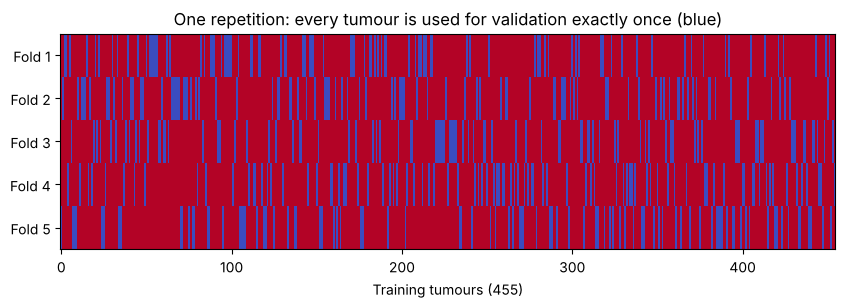

In [5]:
grid = np.zeros((5, len(y_train)))  # one row per fold, one column per tumour
for i in range(5):  # loop over the 5 folds of the first repetition
    grid[i, folds[i][1]] = 1  # mark with 1 the rows that go to validation
plt.figure(figsize=(10, 2.8))  # wide and short figure
plt.imshow(grid, aspect="auto", cmap="coolwarm_r", interpolation="nearest")  # blue = validation, red = training
plt.yticks(range(5), [f"Fold {i + 1}" for i in range(5)])  # name of each row
plt.xlabel("Training tumours (455)")  # horizontal axis
plt.title("One repetition: every tumour is used for validation exactly once (blue)")  # title
plt.savefig(figures_dir / "01_folds.png", bbox_inches="tight")  # save
plt.show()  # show

### Cell 6: the confusion matrix with a hand-made example

**Before the metrics, the confusion matrix.** With an example of 8 tumours we count the four possible cases. The dangerous case is the **false negative** (a malignant tumour that slips away).

In [6]:
y_example = np.array([1, 1, 1, 0, 0, 0, 0, 0])  # 3 truly malignant and 5 truly benign tumours
pred_example = np.array([1, 0, 0, 0, 0, 0, 1, 0])  # what an imaginary model "predicts"
tn, fp, fn, tp = confusion_matrix(y_example, pred_example, labels=[0, 1]).ravel()  # count the four cases
print("True negatives (benign correctly seen):", tn)  # TN
print("False positives (false alarm):", fp)  # FP
print("False negatives (malignant that slips away):", fn)  # FN
print("True positives (malignant detected):", tp)  # TP
print("Recall = TP / (TP + FN) =", round(tp / (tp + fn), 2))  # of the malignant tumours, how many do we catch?
print("Cost = (5·FN + FP) / n =", (5 * fn + fp) / len(y_example))  # a missed malignant tumour weighs 5 times a false alarm

True negatives (benign correctly seen): 4
False positives (false alarm): 1
False negatives (malignant that slips away): 2
True positives (malignant detected): 1
Recall = TP / (TP + FN) = 0.33
Cost = (5·FN + FP) / n = 1.375


### Cell 7: function that computes all the metrics

A single function computes all the metrics. The main one is the **MCC** (Matthews correlation coefficient: 1 = perfect, 0 = no better than chance, −1 = always wrong); it is not fooled by having more benign than malignant tumours.

In [7]:
def compute_metrics(y_true, score, threshold=0.5):  # score = probability of malignant (between 0 and 1)
    pred = (score >= threshold).astype(int)  # say "malignant" if the probability exceeds the threshold
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()  # the four counts
    p = np.clip(score, 1e-6, 1 - 1e-6)  # avoids log(0) in the log-loss
    return {  # return a dictionary with all the metrics
        "mcc": matthews_corrcoef(y_true, pred),  # main metric: balanced even with more benign than malignant
        "recall": tp / (tp + fn),  # fraction of malignant tumours detected
        "precision": tp / (tp + fp) if tp + fp > 0 else 0.0,  # of those we called malignant, how many were
        "f1": f1_score(y_true, pred, zero_division=0),  # harmonic mean of precision and recall
        "accuracy": (tp + tn) / len(y_true),  # fraction of correct predictions (misleading with unequal classes)
        "cost": (5 * fn + fp) / len(y_true),  # average cost per patient (5:1 assumption)
        "fn": int(fn), "fp": int(fp),  # number of false negatives and false positives
        "auc": roc_auc_score(y_true, score),  # quality of the probability ranking (does not depend on the threshold)
        "brier": brier_score_loss(y_true, p),  # squared error of the probabilities (lower = better calibrated)
        "logloss": log_loss(y_true, p, labels=[0, 1]),  # heavily punishes confident, wrong probabilities
    }  # end of the dictionary

for name, value in compute_metrics(y_example, pred_example.astype(float)).items():  # try it on the previous example
    print(f"  {name}: {value:.3f}")  # each metric with 3 decimals

  mcc: 0.149
  recall: 0.333
  precision: 0.500
  f1: 0.400
  accuracy: 0.625
  cost: 1.375
  fn: 2.000
  fp: 1.000
  auc: 0.567
  brier: 0.375
  logloss: 5.181


**What we see:** in the example, 1 of 3 malignant tumours detected (recall 0.33), 5 correct out of 8 (accuracy 0.625) and a cost of 1.375. **Decision:** the report will use **MCC** as the main metric and the **recall of the malignant class** and the **cost** as clinical metrics; accuracy only as a reference.

### Cell 8: function that evaluates a model on the 25 folds

This function is the **heart of the methodology**: for each of the 25 folds it clones the model, trains it on the fold's training part and measures it on its validation part. `summary` computes mean ± standard deviation and the 95% confidence interval.

In [8]:
def evaluate_on_folds(model):  # receives an untrained model
    rows = []  # here we will store the metrics of each fold
    for train_idx, val_idx in folds:  # loop over the 25 folds
        copy = clone(model)  # fresh model that has seen nothing
        copy.fit(X_train[train_idx], y_train[train_idx])  # learns ONLY from the fold's training part
        score = copy.predict_proba(X_train[val_idx])[:, 1]  # probability of malignant on the validation part
        rows.append(compute_metrics(y_train[val_idx], score))  # store this fold's metrics
    return pl.DataFrame(rows)  # table with 25 rows (one per fold)

def summary(table, column):  # mean, standard deviation and 95% interval of a metric
    values = table[column].to_numpy()  # the 25 values
    mean = values.mean()  # mean
    std = values.std(ddof=1)  # standard deviation across folds (dispersion)
    half_ci = stats.t.ppf(0.975, len(values) - 1) * std / np.sqrt(len(values))  # half-width of the 95% CI
    return mean, std, half_ci  # return the three

### Cell 9: baselines (the floor to beat)

**Baselines:** two dumb models. Any useful model must beat them.

In [9]:
baseline_benign = evaluate_on_folds(DummyClassifier(strategy="constant", constant=0))  # always says "benign"
baseline_malignant = evaluate_on_folds(DummyClassifier(strategy="constant", constant=1))  # always says "malignant"
for name, table in [("Always benign", baseline_benign), ("Always malignant", baseline_malignant)]:  # show both
    print(f"{name}: accuracy {table['accuracy'].mean():.3f} | MCC {table['mcc'].mean():.3f} | recall {table['recall'].mean():.3f} | cost {table['cost'].mean():.3f}")  # means over the 25 folds

Always benign: accuracy 0.626 | MCC 0.000 | recall 0.000 | cost 1.868
Always malignant: accuracy 0.374 | MCC 0.000 | recall 1.000 | cost 0.626


**What we see:**

| Baseline | Accuracy | MCC | Recall | Cost |
|---|---|---|---|---|
| Always benign | 0.626 | 0.000 | 0.000 | 1.868 |
| Always malignant | 0.374 | 0.000 | 1.000 | 0.626 |

**Decision:** with accuracy, "always benign" looks decent (62.6%) even though it detects no malignant tumour at all: this is why accuracy misleads. With the 5:1 cost, the floor to beat is **0.626**.

### Cell 10: preprocessing per learner (no data leakage)

**Preprocessing without data leakage.** Some models need standardization (SVM, MLP, evolutionary) and others do not (tree, Naive Bayes). We put them in a `Pipeline`: this way the mean and standard deviation of the scaling are computed **only from the training part of each fold** and then applied to the validation part.

*Data leakage* = the validation data influencing something the model learns (for example, computing the mean with all the data). It makes results look better than they are.

In [10]:
needs_scaling = {"tree": False, "mlp": True, "evolutionary": True, "bayes": False, "svm": True}  # which learners need standardization

def make_pipeline(kind, model, use_log=False):  # joins preprocessing and model in a single piece
    steps = []  # list of preprocessing steps
    if use_log and kind != "tree":  # optional log1p (the tree does not need it)
        steps.append(("log1p", FunctionTransformer(np.log1p)))  # reduces long tails
    if needs_scaling[kind]:  # if the learner measures distances or weights
        steps.append(("scaling", StandardScaler()))  # mean 0 and standard deviation 1
    return Pipeline(steps + [("model", model)])  # preprocessing + model chained

for kind in needs_scaling:  # show which steps each learner has
    print(kind, "->", [name for name, _ in make_pipeline(kind, GaussianNB(), use_log=True).steps])  # step names

tree -> ['model']
mlp -> ['log1p', 'scaling', 'model']
evolutionary -> ['log1p', 'scaling', 'model']
bayes -> ['log1p', 'model']
svm -> ['log1p', 'scaling', 'model']


### Cell 11: check that there is NO data leakage

With an `assert` we check that the scaling of the first fold only knows its training part. If there were ever a leak, the code would stop.

In [11]:
train_idx, val_idx = folds[0]  # first fold
scaler = StandardScaler().fit(X_train[train_idx])  # learns mean and standard deviation ONLY from the fold's training part
print("Does the learned mean match the fold's training mean?", np.allclose(scaler.mean_, X_train[train_idx].mean(axis=0)))  # must be True
print("Is it different from the mean of all the data (with validation)?", not np.allclose(scaler.mean_, X_train.mean(axis=0)))  # must be True
assert np.allclose(scaler.mean_, X_train[train_idx].mean(axis=0))  # if this fails, the code stops
assert not np.allclose(scaler.mean_, X_train.mean(axis=0))  # if this fails, the code stops
print("Check passed: the scaling only sees the training part of each fold.")  # final message

Does the learned mean match the fold's training mean? True
Is it different from the mean of all the data (with validation)? True
Check passed: the scaling only sees the training part of each fold.


**What we see:** the learned mean is that of the fold's training part, not that of all the data. **Decision:** all preprocessing goes inside a `Pipeline`.

### Cell 12: test the machinery with two example models

We test that everything works with two example models. **They are not the final learners** (those are built in Phase 4): they only serve to check the machinery and to have real numbers to illustrate the statistical test.

In [12]:
model_a = make_pipeline("mlp", LogisticRegression(max_iter=1000))  # example A: logistic regression with scaling (NOT one of the 5 learners)
model_b = make_pipeline("bayes", GaussianNB())  # example B: Naive Bayes without scaling
table_a = evaluate_on_folds(model_a)  # evaluate it on the 25 folds
table_b = evaluate_on_folds(model_b)  # same for the other one
for name, table in [("Logistic regression (example)", table_a), ("Naive Bayes (example)", table_b)]:  # show mean ± standard deviation
    mean, std, half = summary(table, "mcc")  # summary of the MCC
    print(f"{name}: MCC = {mean:.3f} ± {std:.3f}  (95% CI: ±{half:.3f})")  # result

Logistic regression (example): MCC = 0.946 ± 0.032  (95% CI: ±0.013)
Naive Bayes (example): MCC = 0.871 ± 0.061  (95% CI: ±0.025)


**What we see:** example A (logistic regression with scaling) reaches an MCC of 0.946 ± 0.032 and example B (Naive Bayes) 0.871 ± 0.061. The **ceiling effect** is already visible (everything very high) and so is the fact that dispersion matters. Important: these numbers belong to the examples only; they are not project results.

### Cell 13: statistical test to compare two models

**When is a difference real?** The 25 folds are not independent (they share rows), so an ordinary t-test comes out too optimistic. The **Nadeau-Bengio corrected t-test** corrects the variance by adding `n_val / n_train`.

In [13]:
def corrected_ttest(a, b, n_train, n_val):  # a and b: per-fold metric of each model
    d = np.asarray(a) - np.asarray(b)  # fold-by-fold difference
    k = len(d)  # number of folds (25)
    variance = d.var(ddof=1)  # variance of the differences
    t = d.mean() / np.sqrt((1 / k + n_val / n_train) * variance)  # corrected t: adds n_val/n_train because the folds overlap
    p = 2 * stats.t.sf(abs(t), df=k - 1)  # two-sided p-value
    return d.mean(), t, p  # mean difference, t statistic and p-value

a = table_a["mcc"].to_numpy()  # per-fold MCC of example A
b = table_b["mcc"].to_numpy()  # per-fold MCC of example B
naive_p = stats.ttest_rel(a, b).pvalue  # ordinary t-test: treats the 25 folds as independent (too optimistic)
diff, t, corrected_p = corrected_ttest(a, b, n_train=len(folds[0][0]), n_val=len(folds[0][1]))  # corrected t-test (Nadeau-Bengio)
print(f"Mean MCC difference (A - B): {diff:+.3f}")  # how much better one is
print(f"p-value of the ordinary t-test:  {naive_p:.4f}")  # comes out smaller than it should
print(f"p-value of the corrected t-test: {corrected_p:.4f}")  # the one we will use

Mean MCC difference (A - B): +0.075
p-value of the ordinary t-test:  0.0000
p-value of the corrected t-test: 0.0180


**What we see:** the mean difference is +0.075 MCC. The ordinary t-test gives p ≈ 0.0000 (almost certain), but the corrected one gives p = 0.018: still significant, but much less emphatic. **Decision:** to compare learners we always use the **corrected** test; with five learners there are 10 comparisons, so the Holm correction will also be applied (Phase 6). On the final test set we will use McNemar.

### Cell 14: choose the decision threshold using the cost

**Decision threshold.** By default a model says "malignant" if the probability exceeds 0.5. Since missing a malignant tumour costs 5 times more, it makes sense to **lower the threshold**. We search for it by minimizing the cost, but **only with training data** (probabilities of tumours that the model did not see while training).

In [14]:
def best_threshold(y_true, score):  # finds the threshold that minimizes the cost
    thresholds = np.linspace(0.01, 0.99, 99)  # 99 possible thresholds
    costs = [compute_metrics(y_true, score, t)["cost"] for t in thresholds]  # cost of each threshold
    return float(thresholds[int(np.argmin(costs))])  # the threshold with the lowest cost

scores = np.zeros(len(y_train))  # here we store one "out-of-sample" probability per tumour
for train_idx, val_idx in folds[:5]:  # use only the first repetition: each tumour appears once in validation
    copy = clone(model_a).fit(X_train[train_idx], y_train[train_idx])  # train on the fold
    scores[val_idx] = copy.predict_proba(X_train[val_idx])[:, 1]  # probabilities of the tumours it did not see
threshold = best_threshold(y_train, scores)  # threshold chosen ONLY with training data
print("Chosen threshold (example):", threshold)  # usually lower than 0.5
print("Cost with threshold 0.5:", round(compute_metrics(y_train, scores, 0.5)["cost"], 3))  # default cost
print("Cost with the chosen threshold:", round(compute_metrics(y_train, scores, threshold)["cost"], 3))  # improved cost

Chosen threshold (example): 0.18000000000000002
Cost with threshold 0.5: 0.097
Cost with the chosen threshold: 0.057


**What we see:** the threshold drops from 0.5 to ~0.18 and the cost of this example goes from 0.097 to 0.057. **Careful:** the threshold is chosen with the same probabilities with which the cost is measured, so that improvement is somewhat optimistic. In Phase 6 the threshold will be fixed with the training set and applied **only once** to the test set.

### Cell 15: diagram of the whole project pipeline

We close the phase with a diagram of the whole project. It shows where each phase fits and, above all, **what each part is allowed to see**.

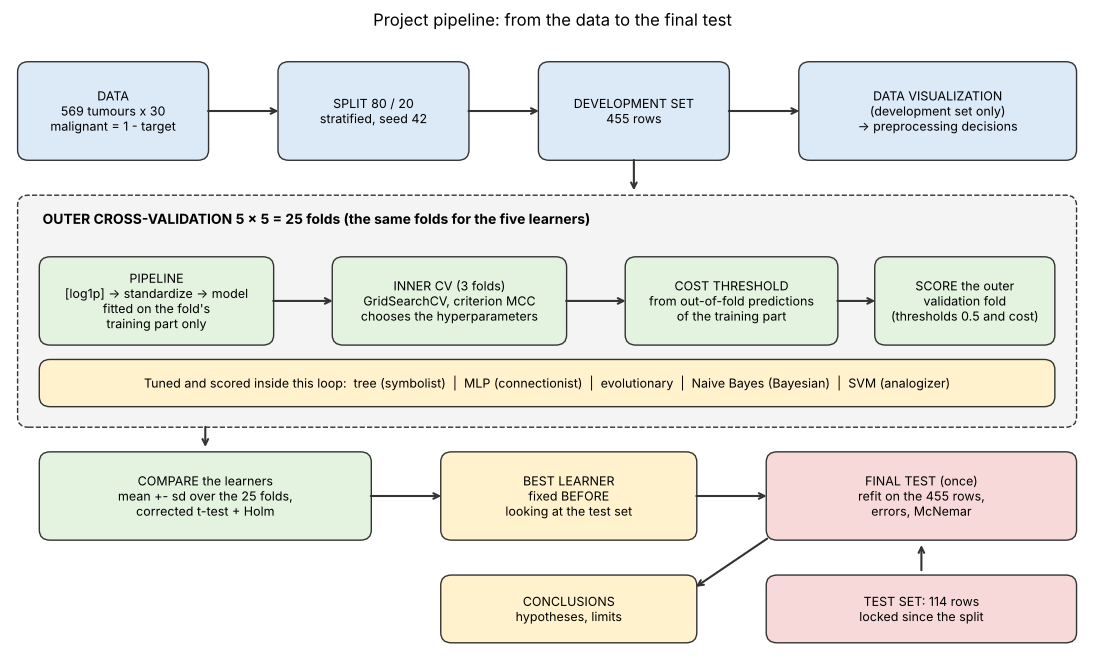

In [15]:
fig, ax = plt.subplots(figsize=(14, 8))  # large canvas for the diagram
ax.set_xlim(0, 100)  # horizontal coordinates from 0 to 100
ax.set_ylim(0, 60)  # vertical coordinates from 0 to 60
ax.axis("off")  # hide the axes: we only want the boxes

def box(x, y, w, h, text, color):  # draws one rounded box with centered text
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1", facecolor=color, edgecolor="#333333"))  # the box
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9)  # the text in its center

def arrow(x1, y1, x2, y2):  # draws one arrow between two points
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#333333", lw=1.5))  # the arrow

box(1, 48, 17, 9, "DATA\n569 tumours x 30\nmalignant = 1 - target", "#DCE9F7")  # the data
box(25, 48, 17, 9, "SPLIT 80 / 20\nstratified, seed 42", "#DCE9F7")  # the split
box(49, 48, 17, 9, "DEVELOPMENT SET\n455 rows", "#DCE9F7")  # the part we may look at
box(73, 48, 25, 9, "DATA VISUALIZATION\n(development set only)\n-> preprocessing decisions", "#DCE9F7")  # exploration
arrow(18, 52.5, 25, 52.5)  # data -> split
arrow(42, 52.5, 49, 52.5)  # split -> development
arrow(66, 52.5, 73, 52.5)  # development -> visualization

ax.add_patch(FancyBboxPatch((1, 22), 97, 22, boxstyle="round,pad=0.3,rounding_size=1", facecolor="#F4F4F4", edgecolor="#333333", linestyle="--"))  # frame of the outer CV
ax.text(3, 42, "OUTER CROSS-VALIDATION 5 x 5 = 25 folds (the same folds for the five learners)", fontsize=10, fontweight="bold", va="center")  # frame title
box(3, 30, 21, 8, "PIPELINE\n[log1p] -> standardize -> model\nfitted on the fold's\ntraining part only", "#E4F2E0")  # preprocessing
box(30, 30, 21, 8, "INNER CV (3 folds)\nGridSearchCV, criterion MCC\nchooses the hyperparameters", "#E4F2E0")  # tuning
box(57, 30, 19, 8, "COST THRESHOLD\nfrom out-of-fold predictions\nof the training part", "#E4F2E0")  # threshold
box(80, 30, 16, 8, "SCORE the outer\nvalidation fold\n(thresholds 0.5 and cost)", "#E4F2E0")  # score
arrow(24, 34, 30, 34)  # pipeline -> tuning
arrow(51, 34, 57, 34)  # tuning -> threshold
arrow(76, 34, 80, 34)  # threshold -> score
box(3, 24, 93, 4, "Tuned and scored inside this loop:  tree (symbolist)  |  MLP (connectionist)  |  evolutionary  |  Naive Bayes (Bayesian)  |  SVM (analogizer)", "#FFF2CC")  # the learners
arrow(57.5, 48, 57.5, 44.5)  # development set -> outer CV

box(3, 11, 30, 8, "COMPARE the learners\nmean +- sd over the 25 folds,\ncorrected t-test + Holm", "#E4F2E0")  # comparison
box(40, 11, 23, 8, "BEST LEARNER\nfixed BEFORE\nlooking at the test set", "#FFF2CC")  # best learner
box(70, 11, 28, 8, "FINAL TEST (once)\nrefit on the 455 rows,\nerrors, McNemar", "#F7D9D9")  # final test
box(70, 1, 28, 6, "TEST SET: 114 rows\nlocked since the split", "#F7D9D9")  # locked test
box(40, 1, 23, 6, "CONCLUSIONS\nhypotheses, limits", "#FFF2CC")  # conclusions
arrow(18, 22, 18, 19.5)  # outer CV -> compare
arrow(33, 15, 40, 15)  # compare -> best
arrow(63, 15, 70, 15)  # best -> final test
arrow(84, 7.5, 84, 10.5)  # locked test -> final test
arrow(70, 11, 63, 6)  # final test -> conclusions
ax.set_title("Project pipeline: from the data to the final test", fontsize=12)  # title
plt.savefig(figures_dir / "02_pipeline.png", bbox_inches="tight")  # save
plt.show()  # show

**What we see:** the data are split first; the visualization uses only the development set; everything that learns (preprocessing, tuning, threshold) lives **inside** the outer cross-validation, so each fold only sees its own training part; the test set stays locked until the best learner is fixed. Phases 4 to 6 fill in these boxes.

## Summary of the Phase 3 decisions

| Topic | Decision |
|---|---|
| Test set | 114 rows (20%), stratified, seed 42, **touched only once** |
| Comparison | **5 × 5** cross-validation = 25 folds, identical for the five learners |
| Hyperparameter tuning | **inner validation with 3 folds** inside each fold (Phase 5) |
| Main metric | **MCC**; also recall of the malignant class, F1, AUC, cost (5·FN + FP)/n, Brier and log-loss |
| Baselines | always benign (cost 1.868) and always malignant (**cost 0.626**: the floor to beat) |
| Dispersion | mean ± standard deviation and 95% CI over the 25 folds |
| Is a difference real? | **corrected** t-test (Nadeau-Bengio) + Holm; McNemar on the final test set |
| Data leakage | all preprocessing inside a `Pipeline` + an `assert` check |
| Preprocessing | tree: none · Bayes: optional `log1p` · SVM, MLP, evolutionary: optional `log1p` + standardization |
| Threshold | chosen by minimizing the cost **with training data**, never with the test set |
| Diagram | the whole pipeline is drawn in `figures/03_methodology/02_pipeline.png` |

**Assumptions we declare:** the 5:1 cost is **our assumption** (taken from german_credit); the 25 folds overlap, which is why the corrected test is needed.

**Next:** Phase 4 · The five learners (with default parameters).